In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.genmod.generalized_linear_model import GLM
from statsmodels.genmod import families
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')
print('Libraries loaded.')

Libraries loaded.


In [2]:
hh  = pd.read_csv('CMST80HH.csv')
per = pd.read_csv('CMST80PER.csv')
print(f'HH records : {len(hh):,}  |  Person records: {len(per):,}')

HH records : 34,950  |  Person records: 142,065


In [3]:
# ── Labels ───────────────────────────────────────────────────────────────────
per['gender_label'] = per['gender'].map({1:'Male', 2:'Female', 3:'Other'})
per['sector_label'] = per['sector'].map({1:'Rural', 2:'Urban'})

state_names = {
    1:'J&K', 2:'HP', 3:'Punjab', 4:'Chandigarh', 5:'Uttarakhand',
    6:'Haryana', 7:'Delhi', 8:'Rajasthan', 9:'UP', 10:'Bihar',
    11:'Sikkim', 12:'Arunachal Pradesh', 13:'Nagaland', 14:'Manipur',
    15:'Mizoram', 16:'Tripura', 17:'Meghalaya', 18:'Assam',
    19:'West Bengal', 20:'Jharkhand', 21:'Odisha', 22:'Chhattisgarh',
    23:'Madhya Pradesh', 24:'Gujarat', 25:'D&NH & DD', 27:'Maharashtra',
    28:'Andhra Pradesh', 29:'Karnataka', 30:'Goa', 31:'Lakshadweep',
    32:'Kerala', 33:'Tamil Nadu', 34:'Puducherry', 35:'A&N Islands',
    36:'Telangana', 37:'Ladakh'
}
per['state_code'] = per['nss_reg'].astype(str).str.zfill(3).str[:2].astype(int)
per['state_name'] = per['state_code'].map(state_names)

# ── Outcome & access variables ────────────────────────────────────────────────
# b4q9: 1/2/3=can use internet, 4=cannot
per['internet_able'] = per['b4q9'].isin([1, 2, 3]).astype(int)
per['used_internet'] = (per['b4q10'] == 1).astype(int)
per['can_email']     = (per['b4q11'] == 1).astype(int)
per['can_bank'] = per['b4q12'].isin([1, 2, 3]).astype(int)

# b4q3: 1=smartphone only, 2=basic only, 3=both, 4=none
per['has_mobile']     = per['b4q3'].isin([1, 2, 3]).astype(int)
per['has_smartphone'] = per['b4q3'].isin([1, 3]).astype(int)
per['no_device']      = ((per['use_mobile']==2) & (per['use_comp']==2)).astype(int)

# ── Digital skill score (0–5, Block 4 Q17–Q21) ───────────────────────────────
skill_qs = ['b4q17', 'b4q18', 'b4q19', 'b4q20', 'b4q21']
per['skill_score'] = sum((per[q] == 1).astype(int) for q in skill_qs)

# ── Age groups ────────────────────────────────────────────────────────────────
per['age_group'] = pd.cut(per['age'], bins=[0,14,24,34,44,59,200],
                          labels=['0-14','15-24','25-34','35-44','45-59','60+'])

# ── Weights & final sample ────────────────────────────────────────────────────
assert (per['mlt'] > 0).all(), "Weight column 'mlt' has zero/negative values"
per_mf = per[per['gender'].isin([1, 2])].copy()
print(f"Sample: {len(per_mf):,} (Male: {(per_mf.gender==1).sum():,} | Female: {(per_mf.gender==2).sum():,})")
print(f"Skill score range: {per_mf.skill_score.min()}–{per_mf.skill_score.max()}")

Sample: 141,865 (Male: 72,309 | Female: 69,556)
Skill score range: 0–5


In [4]:
def wmean(s, w):
    mask = s.notna()
    return np.average(s[mask], weights=w[mask])

indicators = {
    'Any Mobile (last 3 months)'    : 'has_mobile',
    'Smartphone (last 3 months)'    : 'has_smartphone',
    'Able to Use Internet'          : 'internet_able',
    'Used Internet (last 3 months)' : 'used_internet',
    'Can Send Emails'               : 'can_email',
    'Can Do Online Banking'         : 'can_bank',
    'Mean Skill Score (0–5)'        : 'skill_score',
}

rows = []
for label, col in indicators.items():
    m = per_mf[per_mf.gender==1];  f = per_mf[per_mf.gender==2]
    mv = wmean(m[col], m.mlt);     fv = wmean(f[col], f.mlt)
    if col == 'skill_score':
        rows.append({'Indicator':label, 'Male':f'{mv:.3f}', 'Female':f'{fv:.3f}',
                     'Gap(M-F)':f'{mv-fv:.3f}'})
    else:
        rows.append({'Indicator':label, 'Male':f'{mv*100:.1f}%', 'Female':f'{fv*100:.1f}%',
                     'Gap(M-F)':f'{(mv-fv)*100:.1f} pp'})

print('WEIGHTED SUMMARY STATISTICS (NSS multiplier mlt)')
print(pd.DataFrame(rows).set_index('Indicator').to_string())
print(f'\nWeighted population: {per_mf.mlt.sum()/1e6:.0f}M | Sample: {len(per_mf):,}')

WEIGHTED SUMMARY STATISTICS (NSS multiplier mlt)
                                Male Female Gap(M-F)
Indicator                                           
Any Mobile (last 3 months)     84.4%  75.8%   8.7 pp
Smartphone (last 3 months)     71.8%  61.9%   9.8 pp
Able to Use Internet           71.0%  60.4%  10.7 pp
Used Internet (last 3 months)  70.5%  59.8%  10.7 pp
Can Send Emails                37.8%  27.1%  10.7 pp
Can Do Online Banking          44.9%  27.9%  17.0 pp
Mean Skill Score (0–5)         1.647  1.258    0.390

Weighted population: 121911M | Sample: 141,865


## Analysis 1: Digital Access & Usage by Gender

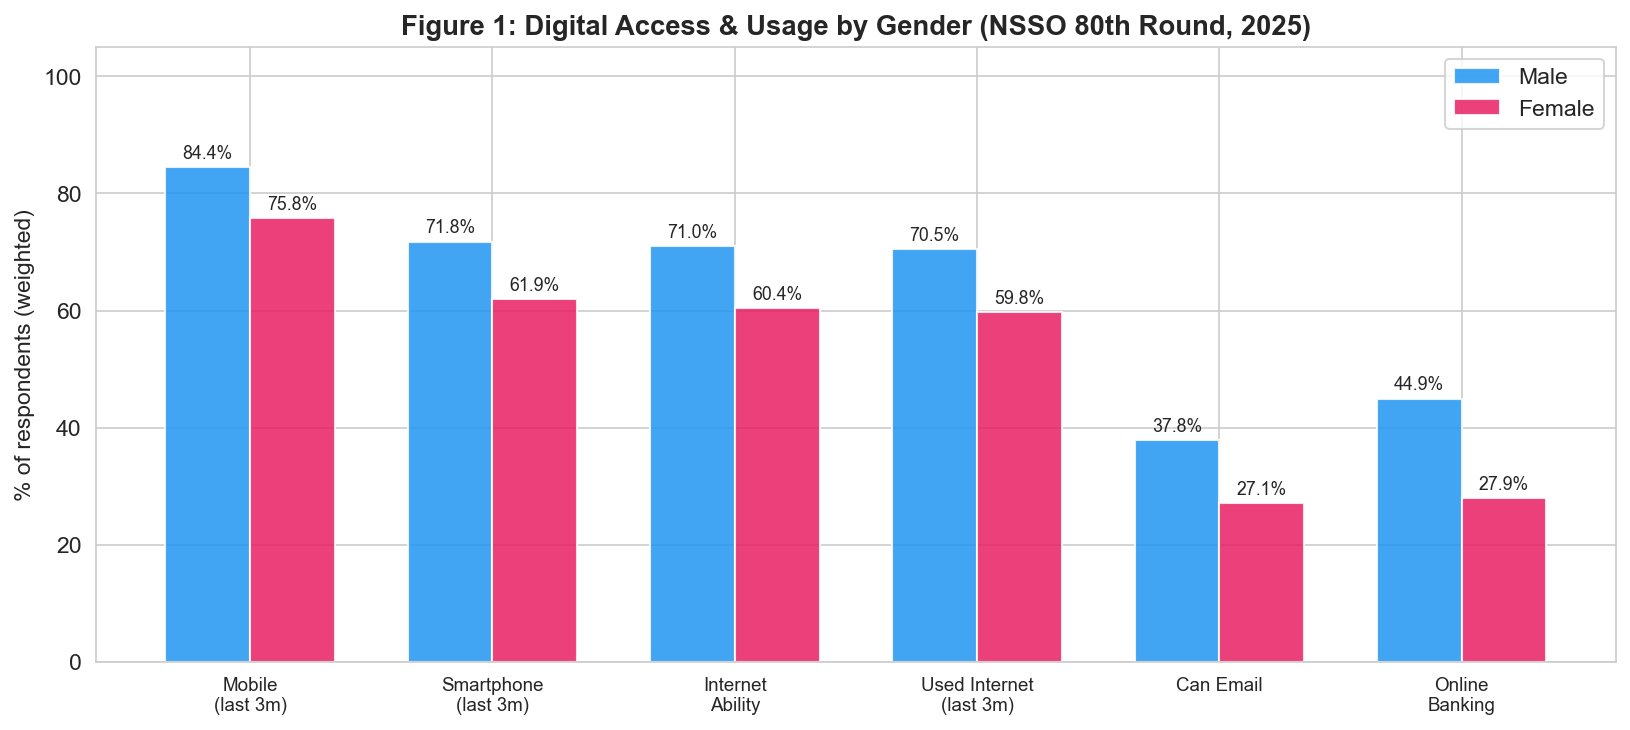

In [5]:
metrics = {
    'Mobile\n(last 3m)':'has_mobile', 'Smartphone\n(last 3m)':'has_smartphone',
    'Internet\nAbility':'internet_able', 'Used Internet\n(last 3m)':'used_internet',
    'Can Email':'can_email', 'Online\nBanking':'can_bank',
}

# Weighted rates
m_df = per_mf[per_mf.gender==1]; f_df = per_mf[per_mf.gender==2]
male_rates   = [wmean(m_df[c], m_df.mlt)*100 for c in metrics.values()]
female_rates = [wmean(f_df[c], f_df.mlt)*100 for c in metrics.values()]
labels = list(metrics.keys())

fig, ax = plt.subplots(figsize=(11, 5))
x, w = np.arange(len(labels)), 0.35
bm = ax.bar(x-w/2, male_rates,   w, label='Male',   color='#2196F3', alpha=0.85)
bf = ax.bar(x+w/2, female_rates, w, label='Female', color='#E91E63', alpha=0.85)
for bar in list(bm)+list(bf):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.8,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel('% of respondents (weighted)'); ax.set_ylim(0,105); ax.legend()
ax.set_title('Figure 1: Digital Access & Usage by Gender (NSSO 80th Round, 2025)', fontweight='bold')
plt.tight_layout(); plt.savefig('figure1_gender_usage.png', bbox_inches='tight'); plt.show()

## Analysis 2: Gender Gap — Rural vs Urban

Internet Ability Rate | Rural gender gap: 11.0 pp
Internet Ability Rate | Urban gender gap: 9.7 pp
Smartphone Use Rate | Rural gender gap: 10.1 pp
Smartphone Use Rate | Urban gender gap: 8.9 pp


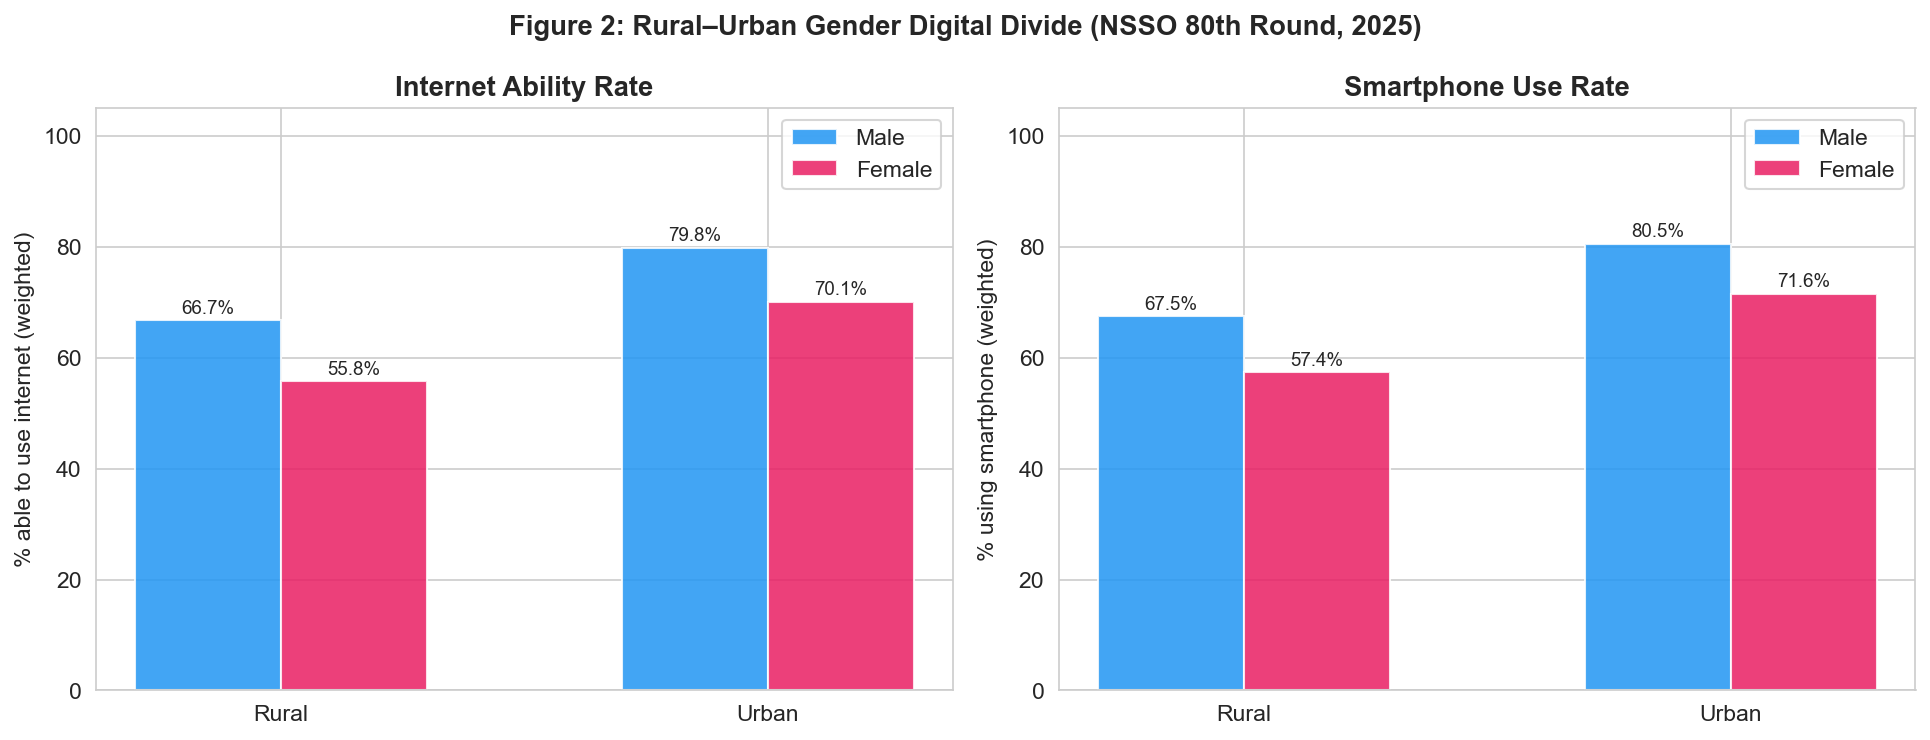

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col, title, ylabel in zip(axes,
    ['internet_able', 'has_smartphone'],
    ['Internet Ability Rate', 'Smartphone Use Rate'],
    ['% able to use internet (weighted)', '% using smartphone (weighted)']):

    rates = {}
    for sector in ['Rural','Urban']:
        for g, glab in [(1,'Male'),(2,'Female')]:
            sub = per_mf[(per_mf.sector_label==sector)&(per_mf.gender==g)]
            rates[(sector,glab)] = wmean(sub[col], sub.mlt)*100

    sectors = ['Rural','Urban']
    x, w2 = np.arange(2), 0.3
    mr = [rates[(s,'Male')]   for s in sectors]
    fr = [rates[(s,'Female')] for s in sectors]
    bm = ax.bar(x-w2/2, mr, w2, color='#2196F3', alpha=0.85, label='Male')
    bf = ax.bar(x+w2/2, fr, w2, color='#E91E63', alpha=0.85, label='Female')
    for bar in list(bm)+list(bf):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(sectors); ax.set_title(title, fontweight='bold')
    ax.set_ylabel(ylabel); ax.legend(); ax.set_ylim(0,105)

    # Print gap
    for s in sectors:
        gap = rates[(s,'Male')] - rates[(s,'Female')]
        print(f'{title} | {s} gender gap: {gap:.1f} pp')

fig.suptitle('Figure 2: Rural–Urban Gender Digital Divide (NSSO 80th Round, 2025)', fontweight='bold')
plt.tight_layout(); plt.savefig('figure2_rural_urban_gender.png', bbox_inches='tight'); plt.show()

## Analysis 3: Digital Skills Score by Gender

Mean skill score — Male: 1.647 | Female: 1.258
t-test: t=45.101, p=0.0000 → SIGNIFICANT


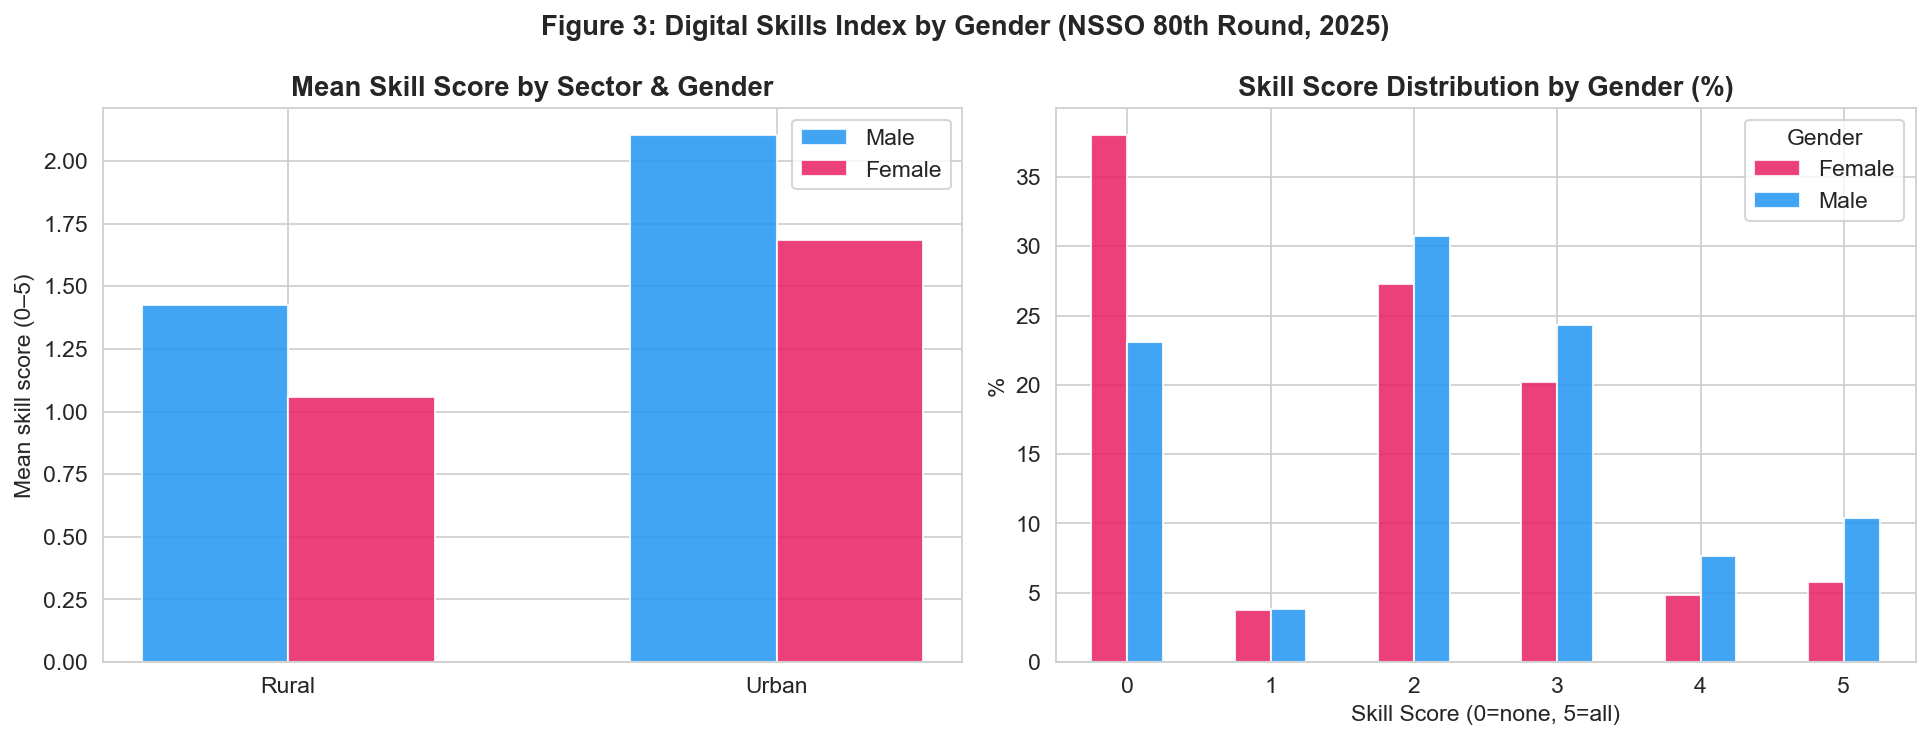

In [7]:
m_df = per_mf[per_mf.gender==1]; f_df = per_mf[per_mf.gender==2]
print(f'Mean skill score — Male: {wmean(m_df.skill_score, m_df.mlt):.3f} | Female: {wmean(f_df.skill_score, f_df.mlt):.3f}')

t_stat, p_val = stats.ttest_ind(m_df.skill_score.dropna(), f_df.skill_score.dropna())
print(f't-test: t={t_stat:.3f}, p={p_val:.4f} → {"SIGNIFICANT" if p_val<0.05 else "not significant"}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: mean by sector × gender (weighted)
ax = axes[0]
data = {}
for sector in ['Rural','Urban']:
    for g, glab in [(1,'Male'),(2,'Female')]:
        sub = per_mf[(per_mf.sector_label==sector)&(per_mf.gender==g)]
        data[(sector,glab)] = wmean(sub.skill_score, sub.mlt)
x, w2 = np.arange(2), 0.3
ax.bar(np.arange(2)-w2/2, [data[('Rural','Male')],data[('Urban','Male')]],
       w2, color='#2196F3', alpha=0.85, label='Male')
ax.bar(np.arange(2)+w2/2, [data[('Rural','Female')],data[('Urban','Female')]],
       w2, color='#E91E63', alpha=0.85, label='Female')
ax.set_xticks([0,1]); ax.set_xticklabels(['Rural','Urban'])
ax.set_title('Mean Skill Score by Sector & Gender', fontweight='bold')
ax.set_ylabel('Mean skill score (0–5)'); ax.legend()

# Right: score distribution
ax2 = axes[1]
per_mf_15 = per_mf[per_mf['age'] >= 15]  # skills only asked to 15+
skill_dist = per_mf_15.groupby(['gender_label','skill_score']).size().unstack('skill_score')
skill_dist_pct = skill_dist.div(skill_dist.sum(axis=1), axis=0) * 100
skill_dist_pct.T.plot(kind='bar', ax=ax2, color=['#E91E63','#2196F3'], alpha=0.85, rot=0)
ax2.set_title('Skill Score Distribution by Gender (%)', fontweight='bold')
ax2.set_xlabel('Skill Score (0=none, 5=all)'); ax2.set_ylabel('%'); ax2.legend(title='Gender')

fig.suptitle('Figure 3: Digital Skills Index by Gender (NSSO 80th Round, 2025)', fontweight='bold')
plt.tight_layout(); plt.savefig('figure3_skill_score.png', bbox_inches='tight'); plt.show()

## Analysis 4: Internet Ability by Age Group

gender_label  Female  Male  Gap(M-F)
age_group                           
0-14            53.0  55.3       2.3
15-24           93.1  96.2       3.1
25-34           88.1  95.3       7.2
35-44           70.1  86.9      16.8
45-59           42.0  64.5      22.5
60+             17.5  32.3      14.7


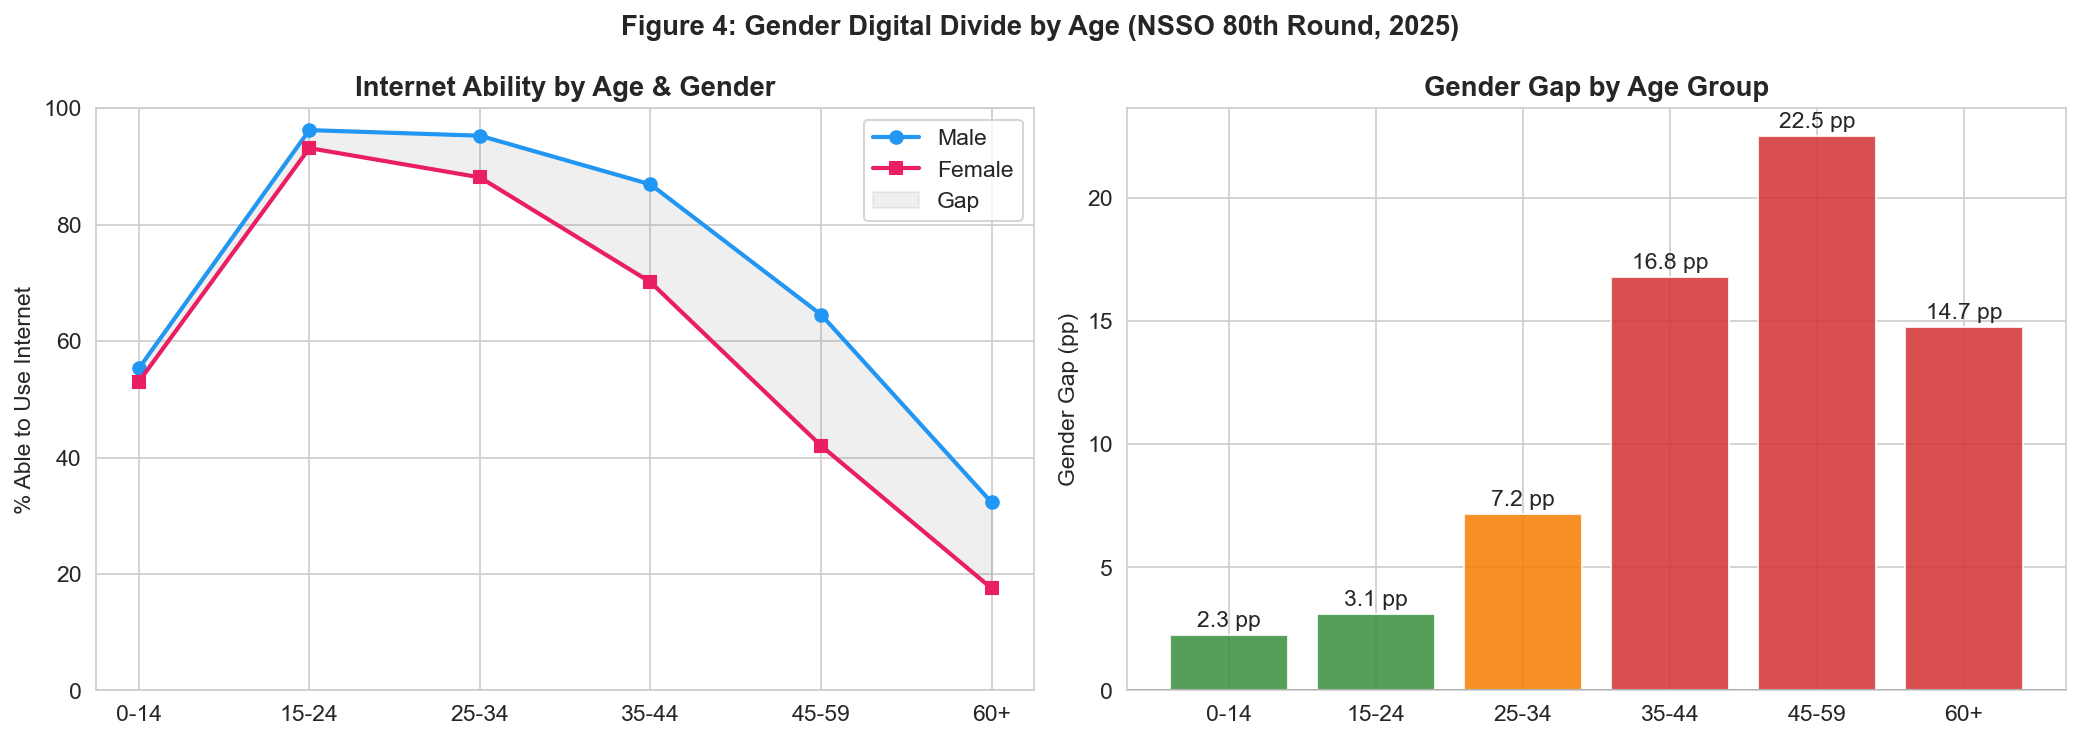

In [8]:
age_internet = per_mf.groupby(['age_group','gender_label'])['internet_able'].mean()*100
age_internet = age_internet.unstack('gender_label')
age_internet['Gap(M-F)'] = age_internet['Male'] - age_internet['Female']
print(age_internet.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.plot(age_internet.index.astype(str), age_internet['Male'],   marker='o', color='#2196F3', lw=2, label='Male')
ax.plot(age_internet.index.astype(str), age_internet['Female'], marker='s', color='#E91E63', lw=2, label='Female')
ax.fill_between(range(len(age_internet)), age_internet['Female'].values, age_internet['Male'].values,
                alpha=0.12, color='gray', label='Gap')
ax.set_xticks(range(len(age_internet))); ax.set_xticklabels(age_internet.index.astype(str))
ax.set_ylabel('% Able to Use Internet'); ax.set_title('Internet Ability by Age & Gender', fontweight='bold')
ax.legend(); ax.set_ylim(0,100)

ax2 = axes[1]
colors = ['#d32f2f' if g>10 else '#f57c00' if g>5 else '#388e3c' for g in age_internet['Gap(M-F)']]
bars = ax2.bar(age_internet.index.astype(str), age_internet['Gap(M-F)'], color=colors, alpha=0.85)
ax2.bar_label(bars, fmt='%.1f pp', padding=2)
ax2.set_ylabel('Gender Gap (pp)'); ax2.set_title('Gender Gap by Age Group', fontweight='bold')
ax2.axhline(0, color='black', lw=0.8)

fig.suptitle('Figure 4: Gender Digital Divide by Age (NSSO 80th Round, 2025)', fontweight='bold')
plt.tight_layout(); plt.savefig('figure4_age_gender_gap.png', bbox_inches='tight'); plt.show()

## Analysis 5: State-wise Gender Gap

Top 5 states (largest gap):
gender_label  Female  Male   Gap
state_name                      
Chandigarh      81.0  96.9  15.8
Lakshadweep     72.4  87.4  14.9
Telangana       61.5  75.1  13.6
A&N Islands     64.2  77.8  13.6
D&NH & DD       68.6  81.7  13.2

Bottom 5 states (smallest gap):
gender_label  Female  Male  Gap
state_name                     
Manipur         76.9  81.8  5.0
Nagaland        67.5  71.8  4.4
Sikkim          82.2  84.2  2.0
Mizoram         86.1  87.1  1.0
Goa             80.4  76.9 -3.4


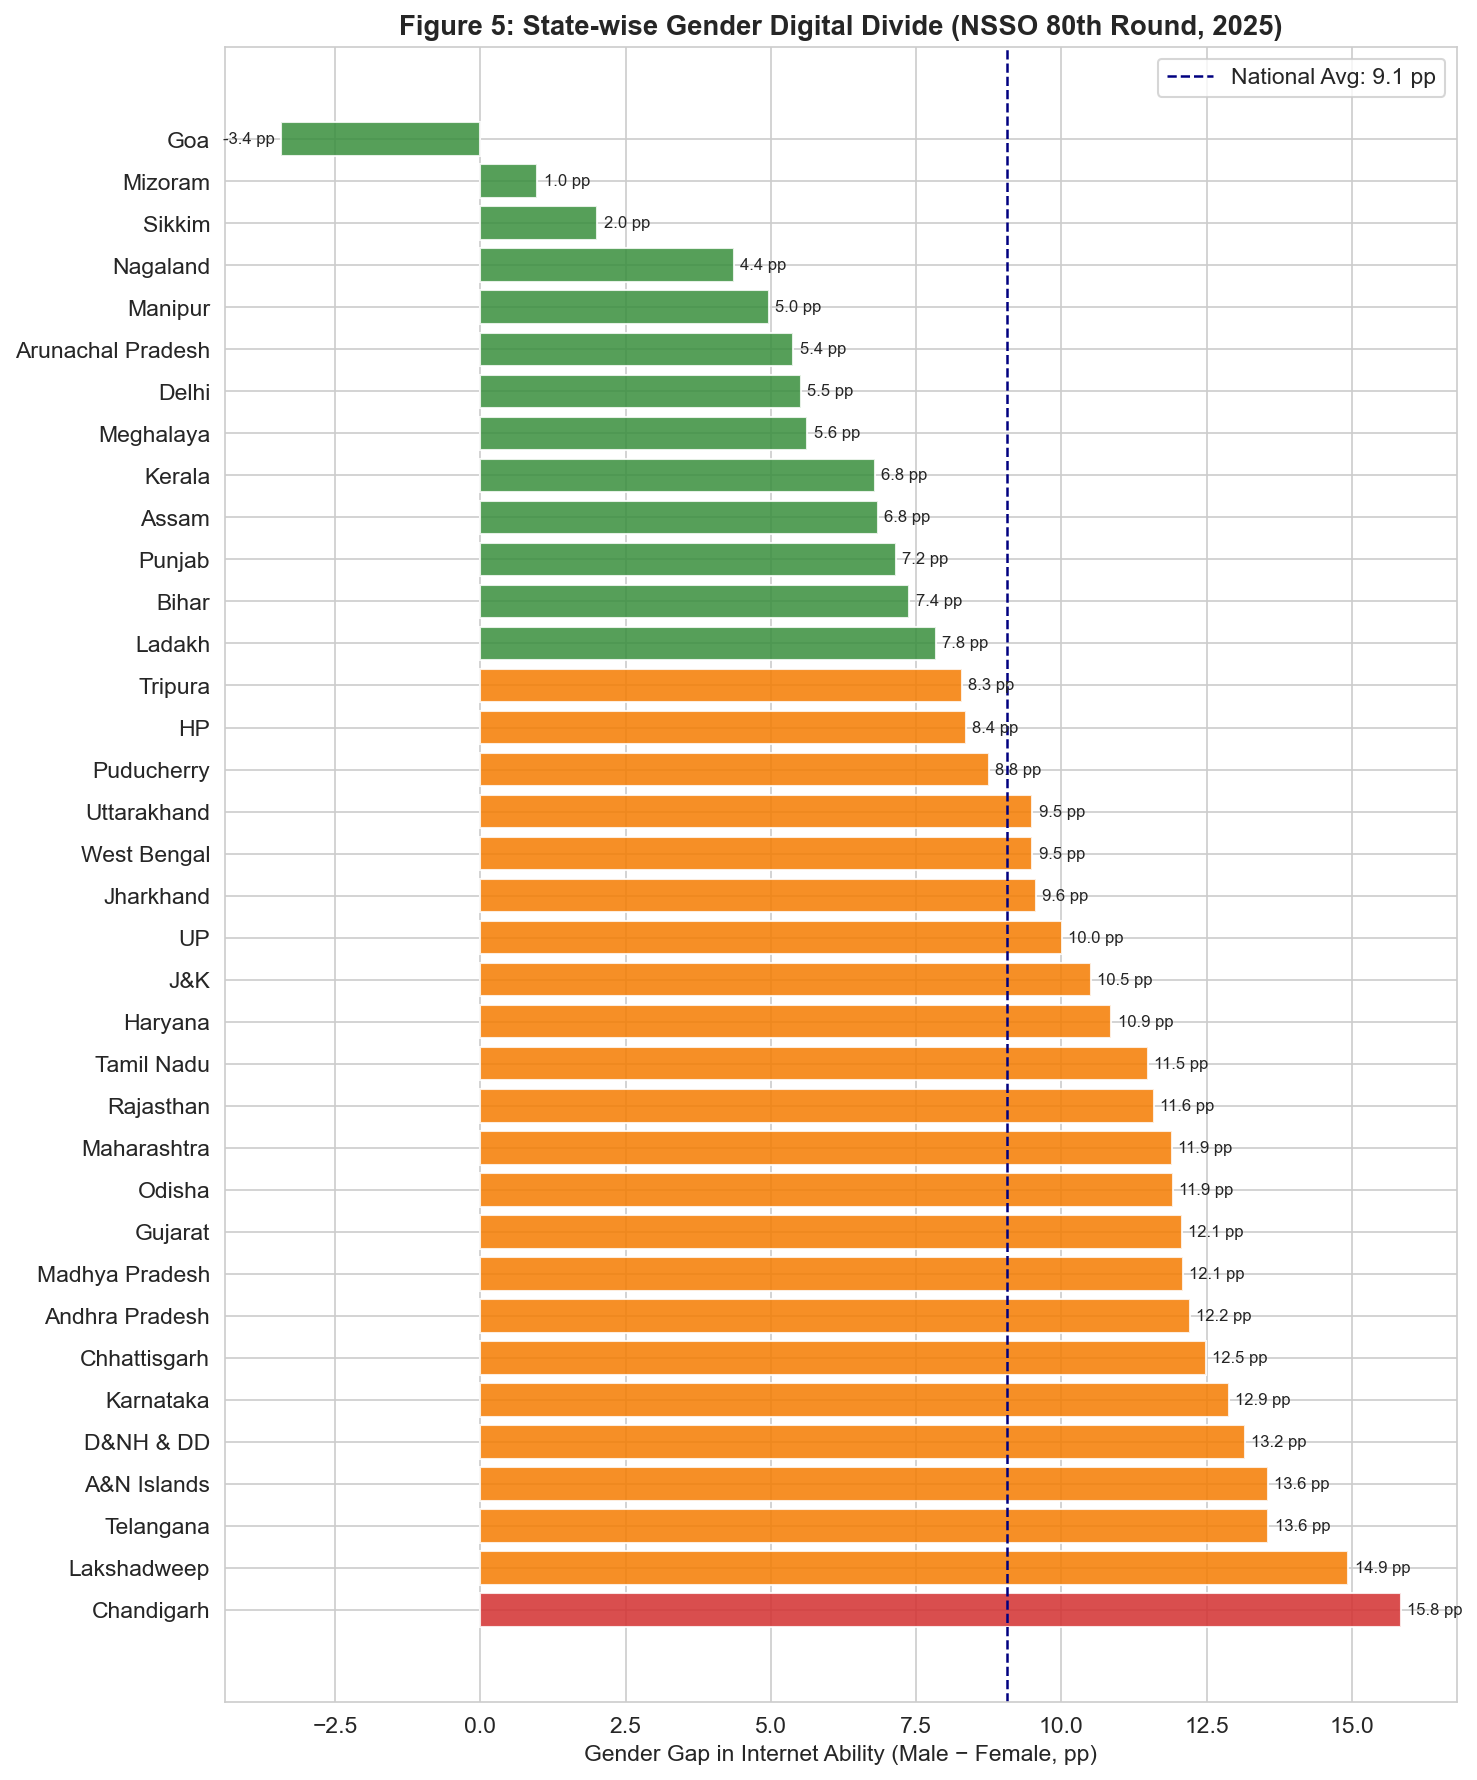

In [9]:
state_gender = per_mf.groupby(['state_name','gender_label'])['internet_able'].mean()*100
state_gender = state_gender.unstack('gender_label').dropna()
state_gender['Gap'] = state_gender['Male'] - state_gender['Female']
state_gender = state_gender.sort_values('Gap', ascending=False)

print('Top 5 states (largest gap):'); print(state_gender.head(5).round(1))
print('\nBottom 5 states (smallest gap):'); print(state_gender.tail(5).round(1))

fig, ax = plt.subplots(figsize=(10, 12))
colors = ['#d32f2f' if g>15 else '#f57c00' if g>8 else '#388e3c' for g in state_gender['Gap']]
bars = ax.barh(state_gender.index, state_gender['Gap'], color=colors, alpha=0.85)
ax.bar_label(bars, fmt='%.1f pp', padding=3, fontsize=8)
ax.axvline(state_gender['Gap'].mean(), color='navy', ls='--', lw=1.2,
           label=f'National Avg: {state_gender["Gap"].mean():.1f} pp')
ax.set_xlabel('Gender Gap in Internet Ability (Male − Female, pp)')
ax.set_title('Figure 5: State-wise Gender Digital Divide (NSSO 80th Round, 2025)', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.savefig('figure5_state_gender_gap.png', bbox_inches='tight'); plt.show()

## Analysis 6: Logistic Regression — What Predicts Internet Ability?

In [10]:
# Merge HH controls
hh_ctrl = hh[['fsu','ssu','b3q2','b3q3','b3q4','b3q5','b5q2']].copy()
hh_ctrl['log_mpce'] = np.log1p(hh_ctrl['b3q5'] / hh_ctrl['b3q2'])
hh_ctrl['is_muslim']   = (hh_ctrl['b3q3'] == 2).astype(int)
hh_ctrl['is_scst']     = (hh_ctrl['b3q4'].isin([1,2])).astype(int)
hh_ctrl['hh_internet'] = (hh_ctrl['b5q2'] == 1).astype(int)

per_reg = per_mf.merge(hh_ctrl[['fsu','ssu','log_mpce','is_muslim','is_scst','hh_internet']],
                        on=['fsu','ssu'], how='left')

reg = per_reg[['internet_able','gender','sector','age','log_mpce','is_muslim','is_scst','hh_internet']].dropna().copy()
reg['female']        = (reg.gender == 2).astype(int)
reg['rural']         = (reg.sector == 1).astype(int)
reg['age_sq']        = reg.age ** 2
reg['rural_x_female']= reg.rural * reg.female

X = sm.add_constant(reg[['female','rural','age','age_sq','rural_x_female','log_mpce','is_muslim','is_scst','hh_internet']])
model_logit = sm.Logit(reg.internet_able, X).fit(disp=0)
print(model_logit.summary())
print('\n=== Average Marginal Effects ===')
print(model_logit.get_margeff().summary())

                           Logit Regression Results                           
Dep. Variable:          internet_able   No. Observations:               141865
Model:                          Logit   Df Residuals:                   141855
Method:                           MLE   Df Model:                            9
Date:                Tue, 26 May 2026   Pseudo R-squ.:                  0.3237
Time:                        15:17:35   Log-Likelihood:                -60823.
converged:                       True   LL-Null:                       -89932.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -9.0047      0.123    -73.333      0.000      -9.245      -8.764
female            -0.6670      0.024    -27.714      0.000      -0.714      -0.620
rural             -0.3775      0.023

## Analysis 7: Probit — Mobile Access → Internet Ability
Adapts Fernandez et al. (2025) UNDP-ICRIER framework to CMST 2025.
- **Digital Access effect**: basic phone vs no device (extensive margin)
- **Digital Inclusion effect**: smartphone vs no device (intensive margin)

In [11]:
# mobile_cat: 0=no device, 1=basic mobile only, 2=smartphone
per_reg['mobile_cat'] = np.nan
per_reg.loc[(per_reg.use_mobile==2)&(per_reg.use_comp==2), 'mobile_cat'] = 0
per_reg.loc[per_reg.b4q3==2,              'mobile_cat'] = 1
per_reg.loc[per_reg.b4q3.isin([1,3]),     'mobile_cat'] = 2
print('mobile_cat:', per_reg.mobile_cat.value_counts(dropna=False).sort_index().to_dict())

results, ape_tables = {}, {}

for sector_code, label in [(1,'Rural'), (2,'Urban')]:
    sub = per_reg[
        (per_reg.sector==sector_code) &
        per_reg.mobile_cat.notna() &
        per_reg.internet_able.notna() &
        per_reg.age.between(15,64)
    ].copy()

    for col in ['log_mpce','hh_internet','is_muslim','is_scst']:
        sub[col] = sub[col].fillna(sub[col].median() if col=='log_mpce' else 0)

    X = sm.add_constant(pd.DataFrame({
        'basic_mobile'   : (sub.mobile_cat==1).astype(float),
        'smartphone'     : (sub.mobile_cat==2).astype(float),
        'female'         : (sub.gender==2).astype(float),
        'age'            : sub.age.astype(float),
        'age_sq'         : (sub.age**2).astype(float),
        'hh_internet'    : sub.hh_internet.astype(float),
        'log_mpce'       : sub.log_mpce.astype(float),
        'is_muslim'      : sub.is_muslim.astype(float),
        'is_scst'        : sub.is_scst.astype(float),
    }))
    y     = sub.internet_able.astype(float)
    w_raw = sub.mlt.astype(float)
    valid = y.notna() & X.notna().all(axis=1) & w_raw.notna()
    X, y, w_raw = X[valid], y[valid], w_raw[valid]
    w_norm = w_raw / w_raw.sum() * len(y)   # normalise weights

    model = GLM(y, X, family=families.Binomial(link=families.links.Probit()),
                var_weights=w_norm).fit(disp=0)
    mfx   = model.get_margeff()
    results[label]    = model
    ape_tables[label] = mfx.summary_frame()
    print(f'\n── {label}  (n={len(y):,}) ──')
    print(mfx.summary())

# Comparison table
print('\n' + '='*72)
print('APE COMPARISON TABLE — Rural vs Urban  (Fernandez et al. Table 1 equivalent)')
print(f"{'Variable':<20} {'Rural APE':>10} {'p':>7} {'Urban APE':>10} {'p':>7}  Note")
print('-'*72)
key = {
    'basic_mobile':'Digital Access   (basic phone vs none)',
    'smartphone'  :'Digital Inclusion (smartphone vs none)',
    'female'      :'Gender penalty',
    'hh_internet' :'Home internet bonus',
    'log_mpce'    :'Household wealth (log MPCE)',
    'is_muslim'   :'Muslim HH',
    'is_scst'     :'SC/ST HH',
}
for var, note in key.items():
    def get(loc, v):
        t = ape_tables[loc]
        if v not in t.index: return float('nan'), float('nan'), ''
        p = t.loc[v,'Pr(>|z|)']
        sig = '***' if p<0.01 else '**' if p<0.05 else '*' if p<0.1 else ''
        return t.loc[v,'dy/dx'], p, sig
    ra,rp,rs = get('Rural',var); ua,up,us = get('Urban',var)
    print(f'{var:<20} {ra:>+9.4f}{rs:<3} {rp:>6.4f}  {ua:>+9.4f}{us:<3} {up:>6.4f}  {note}')
print('Significance: *** p<0.01  ** p<0.05  * p<0.10')
print('Model: GLM Binomial/Probit | Weights: NSS mlt normalised | Baseline: no device')

mobile_cat: {0.0: 20971, 1.0: 17765, 2.0: 96527, nan: 6602}

── Rural  (n=54,462) ──
         GLM Marginal Effects        
Dep. Variable:          internet_able
Method:                          dydx
At:                           overall
                  dy/dx    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
basic_mobile     0.4823    149.293      0.003      0.997    -292.127     293.092
smartphone       0.6766    149.293      0.005      0.996    -291.933     293.286
female          -0.0289      0.002    -17.177      0.000      -0.032      -0.026
age             -0.0029      0.000     -7.254      0.000      -0.004      -0.002
age_sq         1.23e-06      5e-06      0.246      0.806   -8.57e-06     1.1e-05
hh_internet      0.0668      0.003     22.842      0.000       0.061       0.072
log_mpce         0.0179      0.002     10.470      0.000       0.015       0.021
is_muslim       -0.0063      0.003